In [22]:
import os, joblib
print('os:', os.cpu_count(), '| joblib:', joblib.cpu_count())

os: 256 | joblib: 8


In [23]:
import numpy as np
import pandas as pd

df = pd.read_csv("../data/raw/python_seed35.csv")
df.head()

,c2_A,c2_B,c2_C,c2_D,c3_A,c3_B,c3_C,c3_D,KE_ratio
0,-51.802104,-64.980533,-7.799178,-6.380917,1195.595257,1008.110006,381.829998,3262.837090,0.044993
1,-26.469443,-42.855849,-65.605448,-11.000884,1015.970884,449.715700,2151.071819,2451.817895,0.094273
2,-22.733237,-11.475718,-22.446653,-100.469387,3514.710344,2892.059333,2598.618106,2916.890494,2.078388
3,-2.522084,-46.099101,-106.894329,-114.764409,3852.221113,786.243676,3857.037458,3930.949132,0.071775
4,-7.151316,-50.241199,-50.941985,-18.984266,747.833988,2764.590670,3207.227267,537.189349,1.168085


In [24]:
df['Category'] = np.where(((df["c2_A"] ** 2 <= 4 * df["c3_A"]) &
                           (df["c2_B"] ** 2 <= 4 * df["c3_B"]) &
                           (df["c2_C"] ** 2 <= 4 * df["c3_C"]) &
                           (df["c2_D"] ** 2 <= 4 * df["c3_D"])),
                            "het_excl_bist", "het")

In [25]:
df["Category"].value_counts() / df.shape[0]

Category
het_excl_bist    0.829531
het              0.170469
Name: count, dtype: float64

In [26]:
# Perform Log transformation on KE_ratio
# KE_ratio is strictly positive (min ~0.007, max ~2.7) and right-skewed, so a plain log is safe.
# Done on the full dataframe BEFORE the split, so train and test both carry the log_KE_ratio column.
# (A log is a fixed per-row formula, it learns nothing from the data, so doing it first can't leak test info.)
df["log_KE_ratio"] = np.log(df["KE_ratio"])

print("raw skew:", round(df["KE_ratio"].skew(), 3), "| log skew:", round(df["log_KE_ratio"].skew(), 3))

raw skew: 0.907 | log skew: -0.543


In [27]:
# Do stratified train test split based on category
from sklearn.model_selection import train_test_split

FEATURES = ["c2_A", "c2_B", "c2_C", "c2_D", "c3_A", "c3_B", "c3_C", "c3_D"]
TARGET = "log_KE_ratio"   # the model learns log(KE_ratio); np.exp turns predictions back into KE_ratio

# 80/20 split; stratify keeps the het / het_excl_bist proportions identical in train and test
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["Category"], random_state=42
)

X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train_log, y_test_log = train_df[TARGET], test_df[TARGET]

print("train:", train_df.shape, "| test:", test_df.shape)
print(pd.concat([train_df["Category"].value_counts(normalize=True).rename("train"),
                 test_df["Category"].value_counts(normalize=True).rename("test")], axis=1))

train: (288000, 11) | test: (72000, 11)
                  train      test
Category                         
het_excl_bist  0.829531  0.829528
het            0.170469  0.170472


In [28]:
# Initialize Random Forest and decide on parameter grid to search
from sklearn.ensemble import RandomForestRegressor

# n_estimators is fixed rather than searched: more trees only ever helps (slowly), it never overfits.
# n_jobs=-1 parallelizes over trees, so only ONE forest is in memory at a time (a full-depth
# forest here is ~2 GB per 100 trees; 8 forests in parallel could exceed the pod's 16 GB).
rf = RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)

param_grid = {
    # fraction of the 8 features considered at each split (~3, ~5, or all 8)
    "max_features": [0.33, 0.66, 1.0],
    # minimum samples in a leaf: 1 = fully grown trees, larger = smoother predictions
    "min_samples_leaf": [1, 5, 20],
}

In [29]:
# Perform hyperparameter grid search utilizing the 8 workers we have (use joblib to auto detect)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from joblib import cpu_count

n_workers = cpu_count()   # joblib reads the container limit (8), unlike os.cpu_count() (256)
rf.set_params(n_jobs=n_workers)

# Stratify the CV folds by Category too, so each fold has the same het/het_excl_bist mix.
# GridSearchCV can't stratify a regression target itself, so we pass the precomputed splits.
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
cv_splits = list(skf.split(X_train, train_df["Category"]))

grid = GridSearchCV(
    rf,
    param_grid,
    cv=cv_splits,
    scoring="neg_mean_squared_error",   # MSE in log space
    n_jobs=1,          # workers are used inside each forest instead (see memory note above)
    refit=True,        # refit the best params on the full training set at the end
    verbose=3,
)
grid.fit(X_train, y_train_log)

print("best params:", grid.best_params_)
print("best CV MSE (log space):", -grid.best_score_)
pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "std_test_score", "mean_fit_time"]] \
    .sort_values("mean_test_score", ascending=False)

Fitting 3 folds for each of 9 candidates, totalling 27 fits
[CV 1/3] END max_features=0.33, min_samples_leaf=1;, score=-0.125 total time=  10.6s
[CV 2/3] END max_features=0.33, min_samples_leaf=1;, score=-0.124 total time=   9.8s
[CV 3/3] END max_features=0.33, min_samples_leaf=1;, score=-0.124 total time=  10.4s
[CV 1/3] END max_features=0.33, min_samples_leaf=5;, score=-0.137 total time=   8.3s
[CV 2/3] END max_features=0.33, min_samples_leaf=5;, score=-0.137 total time=   8.5s
[CV 3/3] END max_features=0.33, min_samples_leaf=5;, score=-0.139 total time=   7.9s
[CV 1/3] END max_features=0.33, min_samples_leaf=20;, score=-0.169 total time=   6.8s
[CV 2/3] END max_features=0.33, min_samples_leaf=20;, score=-0.168 total time=   6.8s
[CV 3/3] END max_features=0.33, min_samples_leaf=20;, score=-0.170 total time=   7.7s
[CV 1/3] END max_features=0.66, min_samples_leaf=1;, score=-0.110 total time=  21.3s
[CV 2/3] END max_features=0.66, min_samples_leaf=1;, score=-0.109 total time=  21.2s
[C

,params,mean_test_score,std_test_score,mean_fit_time
3,"{'max_features': 0.66, 'min_samples_leaf': 1}",-0.110169,0.000780,20.926991
6,"{'max_features': 1.0, 'min_samples_leaf': 1}",-0.112803,0.001101,37.218518
4,"{'max_features': 0.66, 'min_samples_leaf': 5}",-0.115472,0.000724,17.706205
7,"{'max_features': 1.0, 'min_samples_leaf': 5}",-0.116739,0.001092,28.135520
0,"{'max_features': 0.33, 'min_samples_leaf': 1}",-0.124415,0.000347,9.832251
1,"{'max_features': 0.33, 'min_samples_leaf': 5}",-0.137355,0.000854,7.926786
5,"{'max_features': 0.66, 'min_samples_leaf': 20}",-0.139093,0.000782,15.371017
8,"{'max_features': 1.0, 'min_samples_leaf': 20}",-0.141101,0.001384,26.079954
2,"{'max_features': 0.33, 'min_samples_leaf': 20}",-0.168714,0.000796,6.849912


In [30]:
# Get the best model from the grid seach object and use the methods in src/helper.py to evaluate
import sys
sys.path.append("..")
from src.helper import evalute_model, display_eval

best_rf = grid.best_estimator_

# The model predicts log(KE_ratio). This tiny wrapper exponentiates its predictions so the
# helper (which compares against the raw KE_ratio column) can evaluate on the original scale.
class ExpPredictions:
    def __init__(self, model):
        self.model = model
    def predict(self, X):
        return np.exp(self.model.predict(X))

# 1) Log scale: the scale the model was trained on.
#    The helper always reads the "KE_ratio" column, so hand it a copy where that column holds the log values.
test_df_log = test_df.assign(KE_ratio=test_df["log_KE_ratio"])
print("##### LOG SCALE #####")
display_eval(evalute_model(best_rf, test_df_log))

# 2) Raw KE_ratio scale: the physically meaningful one
print("##### RAW SCALE #####")
display_eval(evalute_model(ExpPredictions(best_rf), test_df))

##### LOG SCALE #####
Model Evaluation over all Data
MSE: 0.10288348712877918
R2:  0.8934178691025281


Model Evaluation over all Heterogeneous Rows
MSE: 0.2317943147165624
R2:  0.7623297164129706


Model Evaluation over all Heterogeneous Rows Excluding Bistability
MSE: 0.07639164943979196
R2:  0.9128483255971968


##### RAW SCALE #####
Model Evaluation over all Data
MSE: 0.01555567791715099
R2:  0.9367723964052963


Model Evaluation over all Heterogeneous Rows
MSE: 0.02019243812950544
R2:  0.8975926906260456


Model Evaluation over all Heterogeneous Rows Excluding Bistability
MSE: 0.014602799859915638
R2:  0.939481543913779




<Axes: >

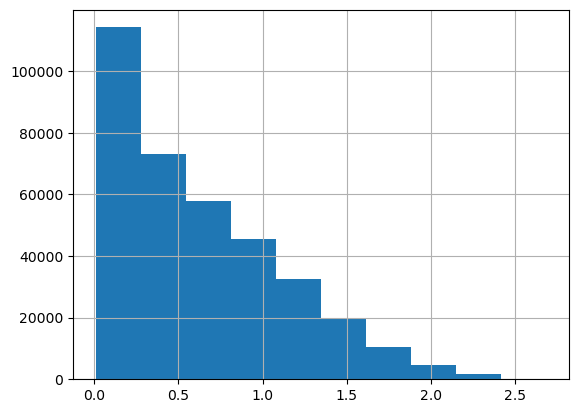

In [33]:
np.exp(df["log_KE_ratio"]).hist()